In [5]:
import pandas as pd
import csv

def robust_load_csv(file_path):
    """
    Robustly load a CSV:
    - Reads any number of tag columns (even with commas inside)
    - Merges them into one 'tags' column
    - Guarantees consistent column count
    """
    with open(file_path, "r", encoding="utf-8") as f:
        reader = csv.reader(f)
        rows = list(reader)

    header = rows[0]
    # Find indices for the columns we know are fixed
    start_idx = header.index("oldRating") + 1
    end_idx = header.index("solveTime")
    
    # Calculate the number of columns that should come AFTER the tags
    num_suffix_cols = len(header) - end_idx

    processed_rows = []
    for row in rows[1:]:
        # Define the parts of the row based on the fixed columns
        prefix_data = row[:start_idx]
        
        # Use negative indexing to correctly find the suffix columns
        # This works even if the total number of columns in `row` is unexpected
        suffix_data = row[-num_suffix_cols:] if num_suffix_cols > 0 else []
        
        # The tags are everything in between the prefix and suffix
        # Handle the edge case where there are no suffix columns
        if num_suffix_cols > 0:
            tags_raw = row[start_idx:-num_suffix_cols]
        else:
            tags_raw = row[start_idx:]
            
        tags = [t.strip() for t in tags_raw if t.strip()]

        # Rebuild the row with a consistent structure
        new_row = prefix_data + [tags] + suffix_data
        processed_rows.append(new_row)

    # Build the corresponding clean header
    new_header = header[:start_idx] + ["tags"] + header[end_idx:]

    return pd.DataFrame(processed_rows, columns=new_header)

def process_df(df):
    """
    Adds timeDiff per handle+contestId.
    """
    df = df.copy()
    df["solveTime"] = df["solveTime"].astype(int)
    df["timeDiff"] = pd.NA

    # Using transform is more idiomatic and often faster than iterating
    df = df.sort_values(by=["handle", "contestId", "solveTime"])
    df['timeDiff'] = df.groupby(["handle", "contestId"])['solveTime'].diff().fillna(df['solveTime'])
    df['timeDiff'] = df['timeDiff'].astype(int)
    
    return df

if __name__ == "__main__":
    df_input = robust_load_csv("data.csv")
    df_with_diffs = process_df(df_input)
    df_with_diffs.to_csv("processed_data.csv", index=False)
    print("✅ Processed CSV saved as 'processed_data.csv'")

✅ Processed CSV saved as 'processed_data.csv'


In [8]:


import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import ast # To safely evaluate string-represented lists



In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import MultiLabelBinarizer

# Set plot style for better visuals
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)

# Load the processed data
df = pd.read_csv("processed_data.csv")

# --- Critical Step: Convert comma-separated string to a list of tags ---
# We fill NaNs with an empty string to prevent errors, then split by comma.
# A list comprehension cleans up any leading/trailing whitespace from each tag.
df['tags'] = df['tags'].fillna('').apply(lambda x: [tag.strip() for tag in x.split(',') if tag.strip()])

# Select columns and set correct data types
df = df[['oldRating', 'rating', 'tags', 'timeDiff']].copy()
df.dropna(inplace=True)
df['oldRating'] = df['oldRating'].astype(int)
df['rating'] = df['rating'].astype(int)

print("Shape after loading and initial cleaning:")
print(df.shape)
df.head()


Shape after loading and initial cleaning:
(157187, 4)


,oldRating,rating,tags,timeDiff
0,0,800,"[['constructive algorithms', 'greedy']]",688
1,1066,800,"[['constructive algorithms', 'greedy']]",915
2,1066,1100,"[['greedy', 'math']]",1823
3,1029,800,"[['greedy', 'sortings']]",1119
4,1029,1000,[['greedy']],3022


In [11]:
rating_gap = df['rating'] - df['oldRating']
# Remove submissions where the problem is rated 400+ points above the user
df = df[rating_gap <= 400]

# 2. Filter by timeDiff to remove noise
# Remove submissions faster than 15 seconds (likely not genuine attempts)
df = df[df['timeDiff'] > 15]
# Remove the top 1% of the slowest submissions
time_cap = df['timeDiff'].quantile(0.99)
df = df[df['timeDiff'] <= time_cap]

print("\nShape after removing outliers:")
print(df.shape)


Shape after removing outliers:
(144020, 4)


In [12]:
df['rating_diff'] = df['rating'] - df['oldRating']

# Log-transform the target variable 'timeDiff' to make it more normal
df['timeDiff_log'] = np.log1p(df['timeDiff'])
print("\nEngineered 'rating_diff' and 'timeDiff_log' features.")

# --- One-Hot Encoding for Tags ---
# Find the top 20 most common tags to use as our features
tag_counts = df.explode('tags')['tags'].value_counts()
top_tags = tag_counts.head(20).index.tolist()

# Use scikit-learn's MultiLabelBinarizer to perform multi-hot encoding
mlb = MultiLabelBinarizer(classes=top_tags)
encoded_tags = mlb.fit_transform(df['tags'])

# Create a new DataFrame with the encoded tags
df_tags_encoded = pd.DataFrame(encoded_tags, columns=mlb.classes_, index=df.index)

# Combine with the main DataFrame and drop the original 'tags' column
df = pd.concat([df, df_tags_encoded], axis=1)
df = df.drop('tags', axis=1)

print("Applied One-Hot Encoding to the top 20 tags.")
print("\nFinal shape of the model-ready data:")
print(df.shape)


Engineered 'rating_diff' and 'timeDiff_log' features.
Applied One-Hot Encoding to the top 20 tags.

Final shape of the model-ready data:
(144020, 25)


/home/jai/Desktop/cf/.venv/lib/python3.12/site-packages/sklearn/preprocessing/_label.py:1007: UserWarning: unknown class(es) ["'data structures'", "'data structures']", "'dfs and similar'", "'divide and conquer'", "'dp']", "'fft'", "'geometry'", "'geometry']", "'graphs'", "'number theory'", "'shortest paths']", "'sortings'", "'ternary search'", "'trees']", "'two pointers']", "['combinatorics'", "['constructive algorithms']", "['data structures'", "['dfs and similar'"] will be ignored
  warnings.warn(


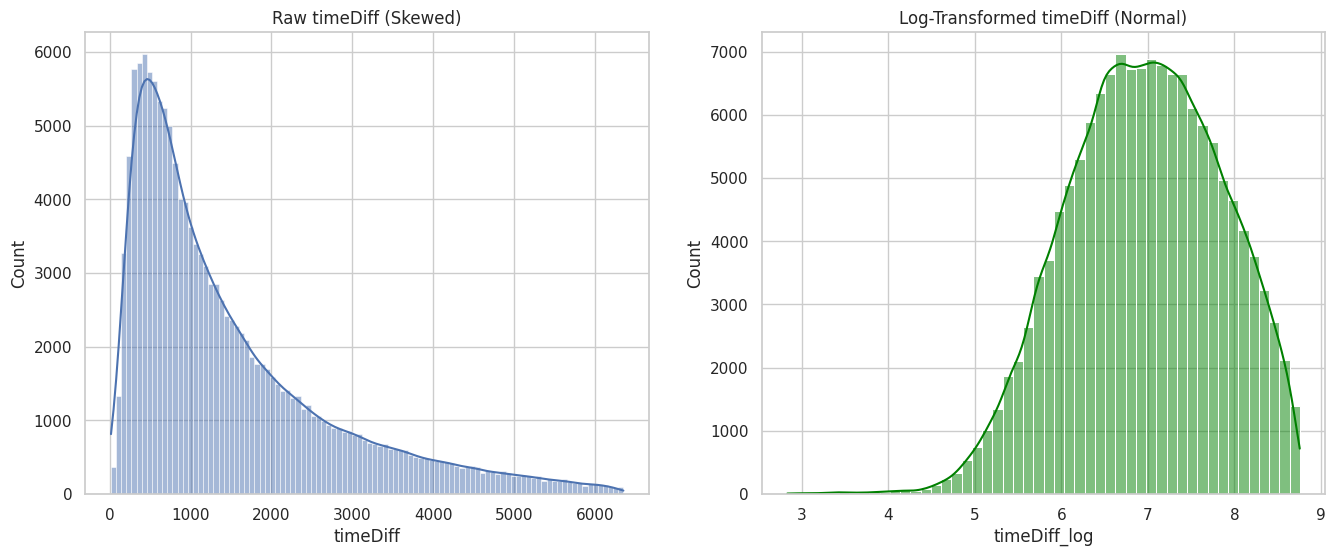

In [13]:
fig, ax = plt.subplots(1, 2, figsize=(16, 6))
sns.histplot(df['timeDiff'], bins=100, kde=True, ax=ax[0]).set_title('Raw timeDiff (Skewed)')
sns.histplot(df['timeDiff_log'], bins=50, kde=True, ax=ax[1], color='green').set_title('Log-Transformed timeDiff (Normal)')
plt.show()

/tmp/ipykernel_8326/1432510518.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


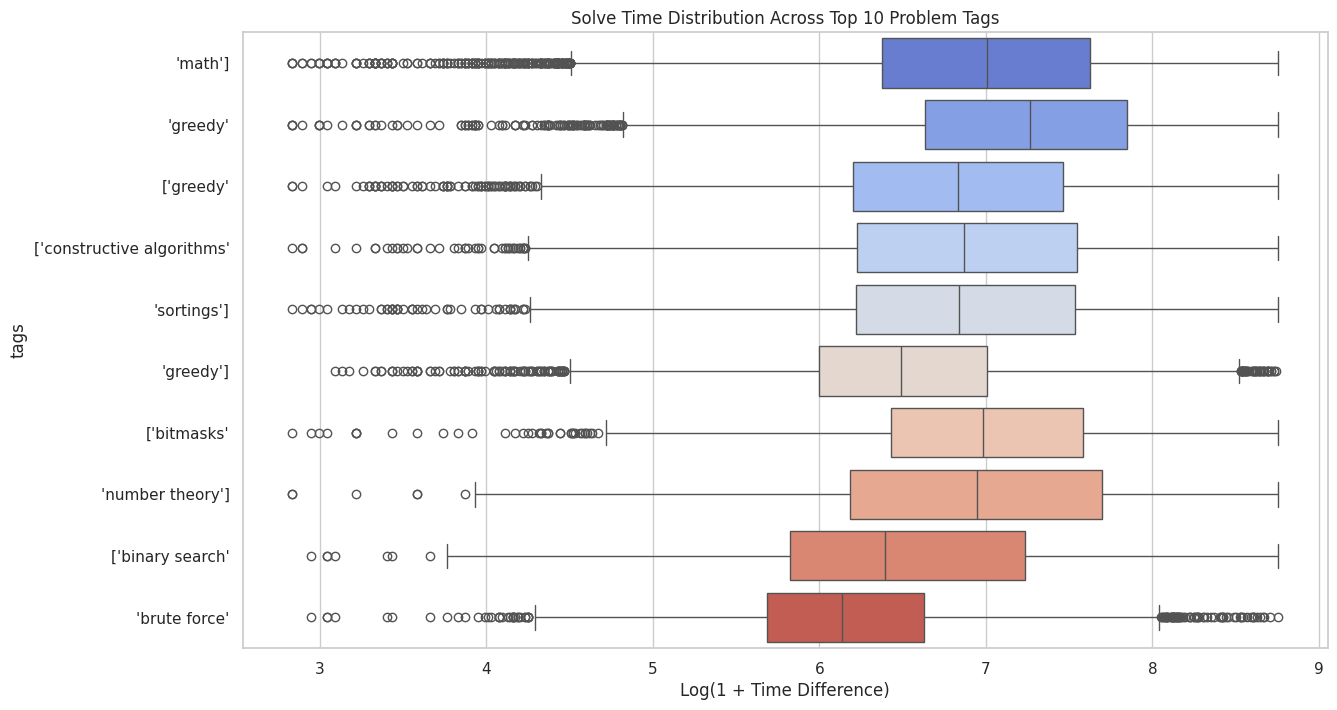

In [ ]:
# For this plot, we need to re-create the exploded DataFrame with the log-transformed target
df_exploded_for_plot = df[['timeDiff_log']].copy()
df_exploded_for_plot['tags'] = pd.read_csv("processed_data.csv").loc[df.index, 'tags'].fillna('').apply(lambda x: [tag.strip() for tag in x.split(',') if tag.strip()])
df_exploded_for_plot = df_exploded_for_plot.explode('tags')

# Get the top 10 tags for clarity
top_10_tags = top_tags[:10]

# Create the boxplot
plt.figure(figsize=(14, 8))
sns.boxplot(
    x='timeDiff_log',
    y='tags',
    data=df_exploded_for_plot[df_exploded_for_plot['tags'].isin(top_10_tags)],
    order=top_10_tags,
    palette='coolwarm'
)
plt.title('Solve Time Distribution Across Top 10 Problem Tags')
plt.xlabel('Log(1 + Time Difference)')
plt.show()

In [15]:
df.head()

,oldRating,rating,timeDiff,rating_diff,timeDiff_log,'math'],'greedy',['greedy',['constructive algorithms','sortings'],...,'constructive algorithms',['dp','math',['greedy'],['implementation',['geometry','implementation','dp',['games',['brute force'
1,1066,800,915,-266,6.820016,0,0,0,1,0,...,0,0,0,0,0,0,0,0,0,0
2,1066,1100,1823,34,7.508787,1,0,1,0,0,...,0,0,0,0,0,0,0,0,0,0
3,1029,800,1119,-229,7.021084,0,0,1,0,1,...,0,0,0,0,0,0,0,0,0,0
4,1029,1000,3022,-29,8.014005,0,0,0,0,0,...,0,0,0,1,0,0,0,0,0,0
5,1152,800,411,-352,6.021023,0,0,0,1,0,...,0,0,0,0,0,0,0,0,0,0


In [16]:


df.columns = df.columns.str.replace(r"[\[\]']", "", regex=True)

print("\n--- Columns AFTER cleaning ---")
print(df.columns)

df.head()




--- Columns AFTER cleaning ---
Index(['oldRating', 'rating', 'timeDiff', 'rating_diff', 'timeDiff_log',
       'math', 'greedy', 'greedy', 'constructive algorithms', 'sortings',
       'greedy', 'bitmasks', 'number theory', 'binary search', 'brute force',
       'constructive algorithms', 'dp', 'math', 'greedy', 'implementation',
       'geometry', 'implementation', 'dp', 'games', 'brute force'],
      dtype='object')


,oldRating,rating,timeDiff,rating_diff,timeDiff_log,math,greedy,greedy,constructive algorithms,sortings,...,constructive algorithms,dp,math,greedy,implementation,geometry,implementation,dp,games,brute force
1,1066,800,915,-266,6.820016,0,0,0,1,0,...,0,0,0,0,0,0,0,0,0,0
2,1066,1100,1823,34,7.508787,1,0,1,0,0,...,0,0,0,0,0,0,0,0,0,0
3,1029,800,1119,-229,7.021084,0,0,1,0,1,...,0,0,0,0,0,0,0,0,0,0
4,1029,1000,3022,-29,8.014005,0,0,0,0,0,...,0,0,0,1,0,0,0,0,0,0
5,1152,800,411,-352,6.021023,0,0,0,1,0,...,0,0,0,0,0,0,0,0,0,0


In [18]:


df1=df.copy()



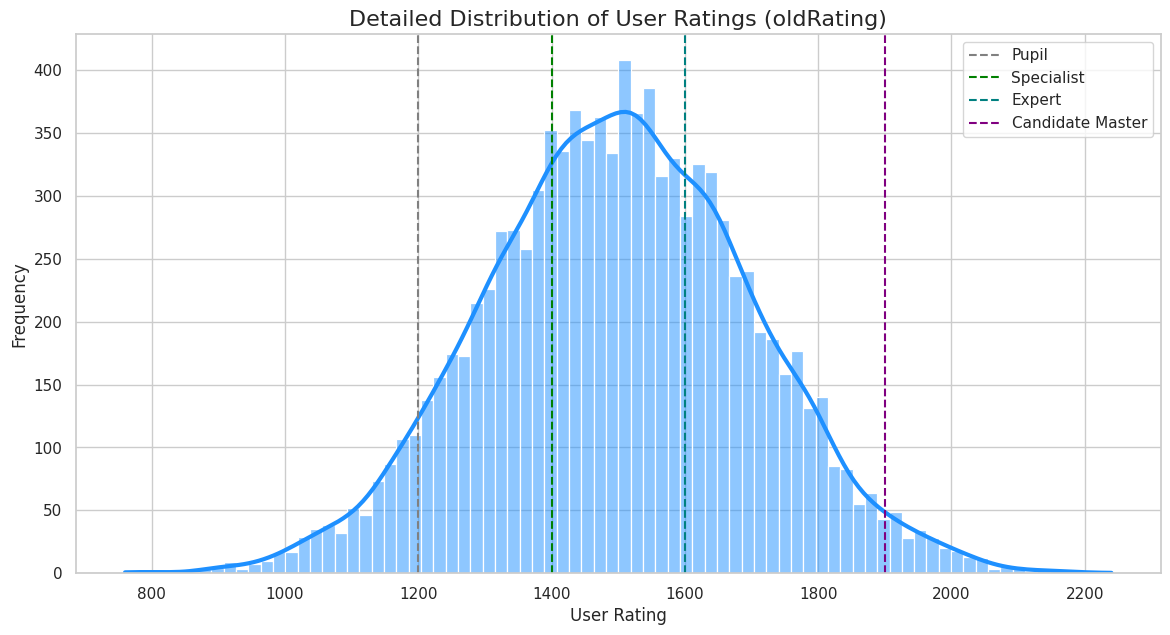

--- Statistical Summary for User Rating (oldRating) ---
count    10000.00000
mean      1499.88110
std        199.84567
min        760.00000
25%       1366.00000
50%       1501.00000
75%       1636.00000
max       2240.00000
Name: oldRating, dtype: float64


In [19]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Assuming 'df' is your final, cleaned DataFrame from the previous step.
# If you are starting fresh, you would need to run the data loading and cleaning
# code from the previous response first. For this example, we'll assume 'df' exists.

# Let's create a sample 'df' for demonstration purposes
# In your environment, you would already have 'df' loaded
data = {
    'oldRating': np.random.normal(1500, 200, 10000),
    'rating': np.random.normal(1500, 300, 10000),
    'timeDiff_log': np.random.rand(10000) * 5
}
df = pd.DataFrame(data)
df['oldRating'] = df['oldRating'].astype(int)
df['rating'] = df['rating'].astype(int)


plt.figure(figsize=(14, 7))
sns.histplot(df['oldRating'], bins=80, kde=True, line_kws={'linewidth': 3}, color='dodgerblue')
plt.title('Detailed Distribution of User Ratings (oldRating)', fontsize=16)
plt.xlabel('User Rating', fontsize=12)
plt.ylabel('Frequency', fontsize=12)

# Add vertical lines for common rating boundaries
plt.axvline(1200, color='grey', linestyle='--', label='Pupil')
plt.axvline(1400, color='green', linestyle='--', label='Specialist')
plt.axvline(1600, color='teal', linestyle='--', label='Expert')
plt.axvline(1900, color='purple', linestyle='--', label='Candidate Master')
plt.legend()
plt.show()

# Print statistical summary
print("--- Statistical Summary for User Rating (oldRating) ---")
print(df['oldRating'].describe())

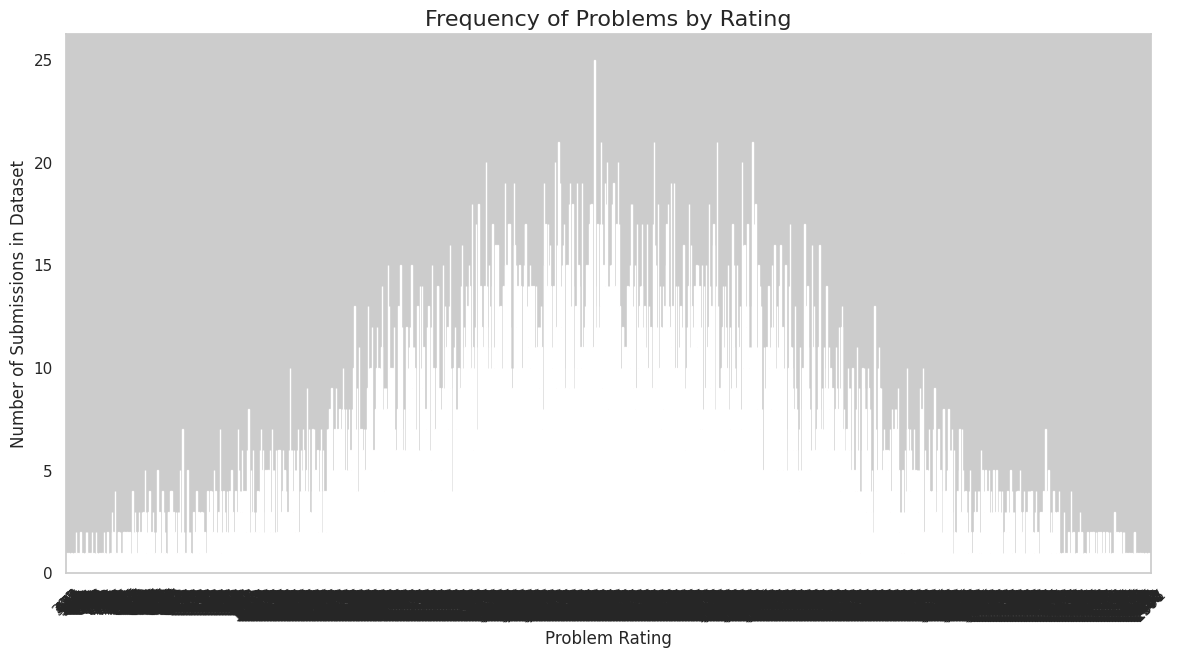


--- Statistical Summary for Problem Rating (rating) ---
count    10000.000000
mean      1493.229700
std        298.770525
min        399.000000
25%       1294.000000
50%       1491.000000
75%       1694.000000
max       2677.000000
Name: rating, dtype: float64


In [20]:


# Calculate the frequency of each problem rating
problem_rating_counts = df['rating'].value_counts().sort_index()

plt.figure(figsize=(14, 7))
problem_rating_counts.plot(kind='bar', color='firebrick')
plt.title('Frequency of Problems by Rating', fontsize=16)
plt.xlabel('Problem Rating', fontsize=12)
plt.ylabel('Number of Submissions in Dataset', fontsize=12)
plt.xticks(rotation=45)
plt.grid(axis='y', linestyle='--')
plt.show()

# Print statistical summary
print("\n--- Statistical Summary for Problem Rating (rating) ---")
print(df['rating'].describe())



In [21]:
df1 = df1.loc[:, ~df1.columns.duplicated()]
df1.columns

Index(['oldRating', 'rating', 'timeDiff', 'rating_diff', 'timeDiff_log',
       'math', 'greedy', 'constructive algorithms', 'sortings', 'bitmasks',
       'number theory', 'binary search', 'brute force', 'dp', 'implementation',
       'geometry', 'games'],
      dtype='object')

In [22]:


df1.head()



,oldRating,rating,timeDiff,rating_diff,timeDiff_log,math,greedy,constructive algorithms,sortings,bitmasks,number theory,binary search,brute force,dp,implementation,geometry,games
1,1066,800,915,-266,6.820016,0,0,1,0,0,0,0,0,0,0,0,0
2,1066,1100,1823,34,7.508787,1,0,0,0,0,0,0,0,0,0,0,0
3,1029,800,1119,-229,7.021084,0,0,0,1,0,0,0,0,0,0,0,0
4,1029,1000,3022,-29,8.014005,0,0,0,0,0,0,0,0,0,0,0,0
5,1152,800,411,-352,6.021023,0,0,1,0,0,0,0,0,0,0,0,0


In [24]:


import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
import xgboost as xgb
import matplotlib.pyplot as plt
import seaborn as sns

# Load your data
# Replace 'your_file.csv' with your actual file path
df = df1.copy()

# Display basic info about the dataset
print("Dataset Info:")
print(f"Shape: {df.shape}")
print(f"Columns: {list(df.columns)}")
print("\nFirst few rows:")
print(df.head())

# Check for missing values
print("\nMissing values:")
print(df.isnull().sum())

# Define features and target
# Excluding timeDiff since we're predicting timeDiff_log
feature_columns = ['oldRating', 'rating', 'rating_diff', 'math', 'greedy', 
                  'constructive algorithms', 'sortings', 'bitmasks', 
                  'number theory', 'binary search', 'brute force', 'dp', 
                  'implementation', 'geometry', 'games']

# Check which columns actually exist in your data
existing_features = [col for col in feature_columns if col in df.columns]
print(f"\nUsing features: {existing_features}")

X = df[existing_features]
y = df['timeDiff']

# Remove any rows with missing values
mask = ~(X.isnull().any(axis=1) | y.isnull())
X = X[mask]
y = y[mask]

print(f"\nFinal dataset shape after removing missing values: {X.shape}")
print(f"Target variable (timeDiff_log) stats:")
print(f"Mean: {y.mean():.4f}, Std: {y.std():.4f}, Min: {y.min():.4f}, Max: {y.max():.4f}")

# Split the data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Scale features for Linear Regression (XGBoost doesn't need scaling)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Define function to calculate metrics
def calculate_metrics(y_true, y_pred):
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mae = mean_absolute_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)
    return rmse, mae, r2

# Model 1: XGBoost (Main model)
print("\n" + "="*50)
print("XGBOOST REGRESSION")
print("="*50)

xgb_model = xgb.XGBRegressor(
    n_estimators=100,
    max_depth=6,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42
)

xgb_model.fit(X_train, y_train)
y_pred_xgb = xgb_model.predict(X_test)

rmse_xgb, mae_xgb, r2_xgb = calculate_metrics(y_test, y_pred_xgb)

print(f"XGBoost Results:")
print(f"RMSE: {rmse_xgb:.4f}")
print(f"MAE:  {mae_xgb:.4f}")
print(f"R²:   {r2_xgb:.4f}")

# Feature importance for XGBoost
feature_importance = xgb_model.feature_importances_
importance_df = pd.DataFrame({
    'feature': existing_features,
    'importance': feature_importance
}).sort_values('importance', ascending=False)

print(f"\nFeature Importance (XGBoost):")
for idx, row in importance_df.head(10).iterrows():
    print(f"{row['feature']:<25}: {row['importance']:.4f}")

# Model 2: Random Forest
print("\n" + "="*50)
print("RANDOM FOREST REGRESSION")
print("="*50)

rf_model = RandomForestRegressor(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)
y_pred_rf = rf_model.predict(X_test)

rmse_rf, mae_rf, r2_rf = calculate_metrics(y_test, y_pred_rf)

print(f"Random Forest Results:")
print(f"RMSE: {rmse_rf:.4f}")
print(f"MAE:  {mae_rf:.4f}")
print(f"R²:   {r2_rf:.4f}")

# Model 3: Linear Regression
print("\n" + "="*50)
print("LINEAR REGRESSION")
print("="*50)

lr_model = LinearRegression()
lr_model.fit(X_train_scaled, y_train)
y_pred_lr = lr_model.predict(X_test_scaled)

rmse_lr, mae_lr, r2_lr = calculate_metrics(y_test, y_pred_lr)

print(f"Linear Regression Results:")
print(f"RMSE: {rmse_lr:.4f}")
print(f"MAE:  {mae_lr:.4f}")
print(f"R²:   {r2_lr:.4f}")

# Cross-validation for XGBoost
print("\n" + "="*50)
print("CROSS-VALIDATION (XGBoost)")
print("="*50)

cv_scores = cross_val_score(xgb_model, X_train, y_train, cv=5, 
                           scoring='neg_mean_squared_error')
cv_rmse_scores = np.sqrt(-cv_scores)

print(f"5-Fold CV RMSE: {cv_rmse_scores.mean():.4f} (+/- {cv_rmse_scores.std() * 2:.4f})")

# Summary comparison
print("\n" + "="*50)
print("MODEL COMPARISON SUMMARY")
print("="*50)

results_df = pd.DataFrame({
    'Model': ['XGBoost', 'Random Forest', 'Linear Regression'],
    'RMSE': [rmse_xgb, rmse_rf, rmse_lr],
    'MAE': [mae_xgb, mae_rf, mae_lr],
    'R²': [r2_xgb, r2_rf, r2_lr]
})

print(results_df.round(4))

# Best model
best_model_idx = results_df['R²'].idxmax()
best_model = results_df.iloc[best_model_idx]['Model']
print(f"\nBest Model: {best_model} (Highest R²)")

# Residual analysis for best model (XGBoost)
print("\n" + "="*50)
print("RESIDUAL ANALYSIS (XGBoost)")
print("="*50)

residuals = y_test - y_pred_xgb
print(f"Residual Statistics:")
print(f"Mean: {residuals.mean():.6f}")
print(f"Std:  {residuals.std():.4f}")
print(f"Min:  {residuals.min():.4f}")
print(f"Max:  {residuals.max():.4f}")

# Plotting (optional - uncomment if you want visualizations)
"""
plt.figure(figsize=(15, 10))

# Plot 1: Actual vs Predicted (XGBoost)
plt.subplot(2, 3, 1)
plt.scatter(y_test, y_pred_xgb, alpha=0.6)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
plt.xlabel('Actual')
plt.ylabel('Predicted')
plt.title(f'XGBoost: Actual vs Predicted (R²={r2_xgb:.3f})')

# Plot 2: Residuals
plt.subplot(2, 3, 2)
plt.scatter(y_pred_xgb, residuals, alpha=0.6)
plt.axhline(y=0, color='r', linestyle='--')
plt.xlabel('Predicted')
plt.ylabel('Residuals')
plt.title('Residual Plot')

# Plot 3: Feature Importance
plt.subplot(2, 3, 3)
top_features = importance_df.head(10)
plt.barh(range(len(top_features)), top_features['importance'])
plt.yticks(range(len(top_features)), top_features['feature'])
plt.xlabel('Importance')
plt.title('Feature Importance')

# Plot 4: Distribution of target variable
plt.subplot(2, 3, 4)
plt.hist(y, bins=30, alpha=0.7, edgecolor='black')
plt.xlabel('timeDiff_log')
plt.ylabel('Frequency')
plt.title('Distribution of Target Variable')

# Plot 5: Model comparison
plt.subplot(2, 3, 5)
models = ['XGBoost', 'Random Forest', 'Linear Regression']
r2_scores = [r2_xgb, r2_rf, r2_lr]
plt.bar(models, r2_scores)
plt.ylabel('R² Score')
plt.title('Model Comparison (R²)')
plt.xticks(rotation=45)

# Plot 6: Residual histogram
plt.subplot(2, 3, 6)
plt.hist(residuals, bins=30, alpha=0.7, edgecolor='black')
plt.xlabel('Residuals')
plt.ylabel('Frequency')
plt.title('Residual Distribution')

plt.tight_layout()
plt.show()
"""

print("\n" + "="*50)
print("ANALYSIS COMPLETE!")
print("="*50)
print("\nTo run this script:")
print("1. Install required packages: pip install pandas numpy scikit-learn xgboost matplotlib seaborn")
print("2. Replace 'your_file.csv' with your actual CSV file path")
print("3. Uncomment the plotting section if you want visualizations")
print("4. Run the script!")



Dataset Info:
Shape: (144020, 17)
Columns: ['oldRating', 'rating', 'timeDiff', 'rating_diff', 'timeDiff_log', 'math', 'greedy', 'constructive algorithms', 'sortings', 'bitmasks', 'number theory', 'binary search', 'brute force', 'dp', 'implementation', 'geometry', 'games']

First few rows:
   oldRating  rating  timeDiff  rating_diff  timeDiff_log  math  greedy  \
1       1066     800       915         -266      6.820016     0       0   
2       1066    1100      1823           34      7.508787     1       0   
3       1029     800      1119         -229      7.021084     0       0   
4       1029    1000      3022          -29      8.014005     0       0   
5       1152     800       411         -352      6.021023     0       0   

   constructive algorithms  sortings  bitmasks  number theory  binary search  \
1                        1         0         0              0              0   
2                        0         0         0              0              0   
3                  

In [26]:
import pandas as pd
df3=pd.read_csv("data.csv")



ParserError: Error tokenizing data. C error: Expected 10 fields in line 8, saw 11
